## 1. Load the Cleaned Dataset

### Objective

To load the cleaned dataset prepared during Exploratory Data Analysis (EDA) and verify its structure before model development.

### Tasks

* Load the cleaned dataset.
* Verify the number of rows and columns.
* Inspect column names and data types.
* Check for missing values and confirm data quality.

### Expected Outcome

A clean and verified dataset ready for feature selection and model preparation.


In [1]:
lazy import pandas as pd
lazy import numpy as np
lazy import matplotlib.pyplot as plt
lazy import seaborn as sns

lazy from sklearn.model_selection import train_test_split, cross_val_score
lazy from sklearn.preprocessing import StandardScaler, OneHotEncoder
lazy from sklearn.linear_model import LinearRegression
lazy from sklearn.compose import ColumnTransformer
lazy from sklearn.pipeline import Pipeline
lazy from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All Important Library are imported Successfully!!")

All Important Library are imported Successfully!!


In [2]:
df = pd.read_csv('../data/processed/df.csv')
print("Dataset loaded successfulyy!")

Dataset loaded successfulyy!


In [3]:
# Processed Dataset has exact 9873 rows and 6 columns
df.shape

(9873, 6)

In [4]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [5]:
df.columns

Index(['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index'],
      dtype='str')

In [6]:
print(df.info())
print(f"Availabe Duplicates in this dataset:{df.duplicated().sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 9873 entries, 0 to 9872
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     9873 non-null   int64  
 1   Previous Scores                   9873 non-null   int64  
 2   Extracurricular Activities        9873 non-null   str    
 3   Sleep Hours                       9873 non-null   int64  
 4   Sample Question Papers Practiced  9873 non-null   int64  
 5   Performance Index                 9873 non-null   float64
dtypes: float64(1), int64(4), str(1)
memory usage: 462.9 KB
None
Availabe Duplicates in this dataset:0


In [7]:
df.rename(columns={'Performance Index': 'Final Marks'}, inplace=True)


C:\Users\shekh\AppData\Local\Temp\ipykernel_19868\426633692.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={'Performance Index': 'Final Marks'}, inplace=True)


## 2. Feature and Target Selection

### Objective

To separate the independent variables (features) from the dependent variable (target).

### Features (X)

* Hours Studied
* Previous Scores
* Sleep Hours
* Sample Question Papers Practiced
* Extracurricular Activities

### Target (y)

* Final Marks

### Expected Outcome

The input features and target variable are defined separately for supervised regression modeling.


In [8]:
X = df.drop(columns='Final Marks')
y = df['Final Marks']

## 3. Feature Type Identification

### Objective

To identify numerical and categorical input features so that appropriate preprocessing techniques can be applied.

### Numerical Features

* Hours Studied
* Previous Scores
* Sleep Hours
* Sample Question Papers Practiced

### Categorical Features

* Extracurricular Activities

### Expected Outcome

The features are categorized according to their data types, enabling the construction of a suitable preprocessing pipeline.


In [9]:
num_col = X.select_dtypes(include=['number'])
cat_col = X.select_dtypes(include=['object','bool','category'])

C:\Users\shekh\AppData\Local\Temp\ipykernel_19868\3722044586.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_col = X.select_dtypes(include=['object','bool','category'])


## 4. Train-Test Split

### Objective

To divide the dataset into training and testing subsets to evaluate the model on unseen data.

### Strategy

* Training set: 80% of the dataset.
* Testing set: 20% of the dataset.
* Use a fixed random state for reproducibility.

### Why Is This Important?

Evaluating a model on unseen data provides a more reliable estimate of its generalization performance than evaluating it only on the training data.

### Expected Outcome

Separate training and testing datasets are prepared for model development and evaluation.


In [10]:
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.2)

In [11]:
X_train


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced
8495,5,71,No,4,4
9012,2,57,Yes,7,1
4092,1,49,No,4,0
811,3,58,Yes,6,1
6789,3,80,No,8,8
...,...,...,...,...,...
5734,2,46,No,6,5
5191,9,60,Yes,4,3
5390,5,95,Yes,5,6
860,1,47,No,9,0


In [12]:
X_test

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced
6057,4,64,Yes,5,5
106,7,90,Yes,4,1
9154,6,73,Yes,6,1
4680,3,43,No,6,8
2149,9,76,No,9,8
...,...,...,...,...,...
8634,2,42,Yes,4,7
3100,3,60,Yes,5,9
5267,2,99,Yes,8,1
6074,7,94,Yes,6,6


In [13]:
y_train

8495    56.0
9012    35.0
4092    19.0
811     41.0
6789    59.0
        ... 
5734    22.0
5191    56.0
5390    81.0
860     20.0
7270    82.0
Name: Final Marks, Length: 7898, dtype: float64

In [14]:
y_test

6057    47.0
106     76.0
9154    62.0
4680    23.0
2149    76.0
        ... 
8634    19.0
3100    39.0
5267    77.0
6074    88.0
5058    34.0
Name: Final Marks, Length: 1975, dtype: float64

## 5. Categorical Feature Encoding

### Objective

To convert categorical input features into a numerical representation suitable for machine learning algorithms.

### Technique

One-Hot Encoding will be applied to the Extracurricular Activities feature.

### Why Is It Required?

Most scikit-learn regression models require numerical input features. One-hot encoding represents categories numerically without introducing an artificial ranking between Yes and No.

### Expected Outcome

The categorical feature is transformed into a model-compatible representation.


In [15]:
num_col = X_train.select_dtypes(include=['number']).columns.to_list()
cat_col = X_train.select_dtypes(include=['object','bool','category']).columns.to_list()



C:\Users\shekh\AppData\Local\Temp\ipykernel_19868\4170544436.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_col = X_train.select_dtypes(include=['object','bool','category']).columns.to_list()


## 5. Create ColumnTransformer

### Objective

To define separate preprocessing strategies for numerical and categorical features using Scikit-learn's ColumnTransformer.

### Numerical Features

* Hours Studied
* Previous Scores
* Sleep Hours
* Sample Question Papers Practiced

### Categorical Features

* Extracurricular Activities

### Preprocessing Strategy

* Numerical features: Retain their original values for the initial Linear Regression baseline.
* Categorical features: Apply One-Hot Encoding to convert categories into a numerical representation.
* ColumnTransformer: Apply the appropriate transformation to each selected group of columns.

### Expected Outcome

A configured ColumnTransformer that can preprocess numerical and categorical input features appropriately.


In [16]:
# Column Transformer

preprocessor = ColumnTransformer(
    transformers=[
        ('cat',OneHotEncoder(handle_unknown='ignore'),cat_col),
        ('num',StandardScaler(),num_col)
        
        
    ]
)

## 6. Create Machine Learning Pipeline

### Objective

To combine the preprocessing component and Linear Regression model into a single Scikit-learn Pipeline.

### Pipeline Components

**1. Preprocessing Step**
Uses the ColumnTransformer defined in the previous step to transform numerical and categorical features.

**2. Model Training Step**
Uses Linear Regression to learn the relationship between the processed features and the target variable, Performance Index.

### Advantages

* Combines preprocessing and model training into one workflow.
* Reduces the risk of data leakage when fitted correctly.
* Ensures consistent transformations during training and prediction.
* Simplifies model evaluation and deployment.

### Expected Outcome

A complete machine learning pipeline that accepts the original input features and predicts Performance Index.


In [17]:
pipe = Pipeline([('Preprocessor',preprocessor),
                 ('Model', LinearRegression())
                ])

## 8. Train the Linear Regression Model

### Objective

To train the Linear Regression model using the integrated preprocessing pipeline.

### Process

* Fit the pipeline on the training features and target variable.
* Allow the preprocessing component to learn the required transformations from the training data.
* Train the Linear Regression model on the transformed features.

### Expected Outcome

A fitted machine learning pipeline that learns the relationship between student-related features and Performance Index.


In [18]:
pipe.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessor', ...), ('Model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Hours Studied','Previous Scores','Extracurricular Activities', 'Sleep Hours','Sample Question Papers Practiced']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatical

## 9. Generate Predictions

### Objective

To generate Performance Index predictions for the unseen testing dataset using the trained machine learning pipeline.

### Process

* Pass the test features to the trained pipeline.
* Generate predicted Performance Index values.
* Compare actual and predicted values for selected observations.

### Expected Outcome

The model generates predictions for unseen data, preparing the results for evaluation.


In [19]:
prediction = pipe.predict(X_test)

prediction[0:10]

array([46.48001281, 80.2853795 , 61.06518835, 22.706315  , 74.8368676 ,
       84.19496789, 61.99314117, 50.33744319, 38.89868104, 55.75320202])

## 10. Model Evaluation

### Objective

To evaluate the predictive performance of the Linear Regression model on unseen testing data.

### Evaluation Metrics

**1. Mean Absolute Error (MAE)**
Measures the average absolute difference between actual and predicted Performance Index values.

**2. Mean Squared Error (MSE)**
Measures the average squared difference between actual and predicted values.

**3. Root Mean Squared Error (RMSE)**
Measures prediction error in the same units as the target variable.

**4. R² Score**
Measures model performance relative to predicting the mean target value.

### Interpretation

Lower MAE, MSE, and RMSE generally indicate smaller prediction errors. A higher R² generally indicates better performance relative to the mean-prediction baseline.

### Expected Outcome

The model's predictive performance is quantified using multiple evaluation metrics.


In [20]:
mae = mean_absolute_error(y_test,prediction)
mse = mean_squared_error(y_test,prediction)
r2 = r2_score(y_test,prediction)


print("Mean Absolute Error:",mae)
print("Mean Squared Error:",mse)
print("R2 Score:",r2)

Mean Absolute Error: 1.6469703984255573
Mean Squared Error: 4.305900938538476
R2 Score: 0.9884301209927054


## 10.1 Evaluation Results and Interpretation

### Results

* Mean Absolute Error (MAE): 1.6469
* Mean Squared Error (MSE): 4.3059
* Root Mean Squared Error (RMSE): 2.0750 (approximately)
* R² Score: 0.9884

### Observations

1. The model's average absolute prediction error is approximately 1.65 Performance Index points.
2. The RMSE is approximately 2.08 points, indicating the scale of prediction errors while penalizing larger errors more heavily than MAE.
3. The R² score indicates that the model explains approximately 98.84% of the variation in Performance Index on the test dataset.

### Conclusion

The Linear Regression model demonstrates strong predictive performance on the held-out test dataset.

However, the high R² score should be interpreted alongside the dataset's source, target-generation process, and potential limitations. Further error analysis and validation are required before concluding that the model will perform equally well on real-world student data.


## 11. Actual vs Predicted Analysis

### Objective

To visually evaluate the agreement between actual Performance Index values and the values predicted by the Linear Regression model.

### Analysis

* Compare actual and predicted values using a scatter plot.
* Include a reference line representing perfect predictions.
* Observe how closely the points follow the reference line.
* Identify areas where prediction errors appear larger.
* Check for systematic overprediction or underprediction.

### Expected Outcome

A visual assessment of the model's prediction quality and potential weaknesses across different Performance Index values.


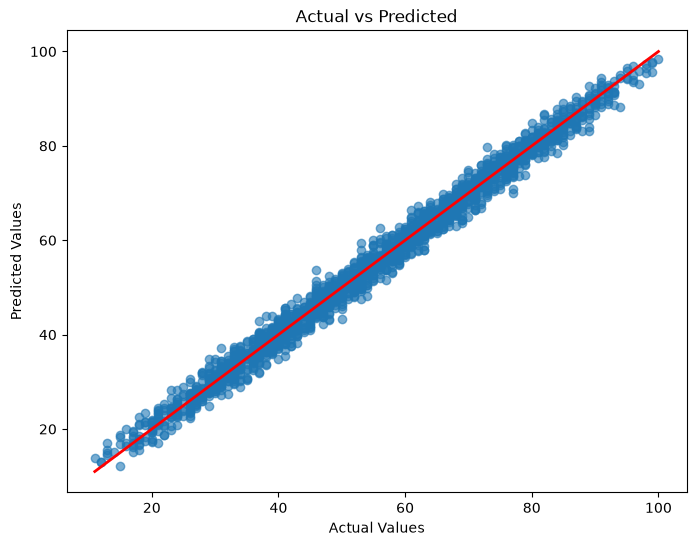

In [21]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, prediction, alpha=0.6)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linewidth=2
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted")
plt.show()

## 11.1 Observations: Actual vs Predicted

* Most data points lie close to the ideal prediction line.
* The model demonstrates strong agreement between actual and predicted Performance Index values.
* Most predictions appear reasonably close to their corresponding actual values.
* Some deviations from the reference line indicate that prediction errors still exist.
* The visualization is consistent with the high R² score obtained during model evaluation.

### Conclusion

The Actual vs Predicted plot suggests that the Linear Regression model fits the test data well. However, further residual analysis and validation are required to assess generalization performance.


## 12. Residual Analysis

### Objective

To investigate prediction errors and identify potential patterns that may indicate limitations in the Linear Regression model.

### Analysis

* Calculate residuals as actual values minus predicted values.
* Plot residuals against predicted values.
* Examine the residual distribution.
* Check for systematic patterns or changing error variance.
* Identify observations with relatively large prediction errors.

### Expected Outcome

An understanding of prediction errors and whether the model's assumptions appear reasonable for the dataset.


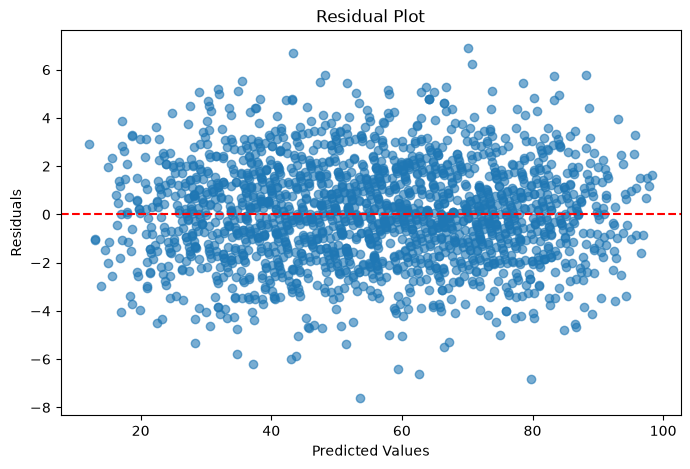

In [22]:
residuals = y_test - prediction

plt.figure(figsize=(8,5))
plt.scatter(prediction, residuals, alpha=0.6)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

## 13 Cross-Validation Results and Interpretation

In [23]:
cv_scores = cross_val_score(
    pipe,
    X_train,
    y_train,
    cv=5,
    scoring='r2'
)

print("CV R² Scores:", cv_scores)
print("Mean CV R²:", cv_scores.mean())
print("Std CV R²:", cv_scores.std())

CV R² Scores: [0.98831172 0.98852894 0.98904679 0.98857308 0.98912507]
Mean CV R²: 0.9887171183901646
Std CV R²: 0.0003148381157811366



### Results

* Number of Folds: 5
* Mean Cross-Validation R²: 0.9887
* Standard Deviation of R²: 0.00031

### Observations

1. The model achieved a high mean R² score across five validation folds.
2. The standard deviation is very low, indicating consistent performance across these folds.
3. The results suggest that the model captures a strong relationship between the input features and Performance Index.

### Conclusion

The Linear Regression pipeline demonstrates strong and consistent performance across the five cross-validation folds. However, further model comparison and verification of the dataset's target-generation process are necessary before drawing conclusions about real-world generalization.


## 14. Regression Model Comparison

### Objective

To compare multiple regression algorithms against the baseline Linear Regression model for predicting Performance Index.

### Candidate Models

* Linear Regression
* Ridge Regression
* Decision Tree Regressor
* Random Forest Regressor
* Gradient Boosting Regressor

### Evaluation Strategy

* Use the same training dataset for all candidate models.
* Apply appropriate preprocessing through a separate pipeline for each model.
* Compare performance using MAE, RMSE, and R².
* Use cross-validation on the training data for fair model selection.
* Reserve the test dataset for final evaluation.

### Expected Outcome

A structured comparison of regression algorithms to determine whether alternative models provide meaningful improvements over Linear Regression.


In [24]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

results = []

for name,model in models.items():
    pipe = Pipeline([('Preprocessor',preprocessor),
                 ('Model', model)
                ])
    
    pipe.fit(X_train,y_train)
    pred = pipe.predict(X_test)
    
    mae = mean_absolute_error(y_test,pred)
    mse = mean_squared_error(y_test,pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test,pred)
    
    cv_score = cross_val_score(
        pipe,
        X_train,
        y_train,
        cv=10,
        scoring='r2'
    ).mean()
    
    results.append([
        name,
        mae,
        mse,
        rmse,
        r2,
        cv_score
    ])
    
results_df = pd.DataFrame(
    results,
    columns=[
        "Name",
        "MAE",
        "MSE",
        "RMSE",
        "R2",
        "CV_R2"
    ]
)

results_df

,Name,MAE,MSE,RMSE,R2,CV_R2
0,Linear Regression,1.646970,4.305901,2.075066,0.988430,0.988695
1,Ridge Regression,1.646956,4.305953,2.075079,0.988430,0.988695
2,Decision Tree,2.434768,9.316765,3.052338,0.974966,0.974546
3,Random Forest,1.896141,5.620594,2.370779,0.984898,0.984920
4,Gradient Boosting,1.695763,4.575901,2.139136,0.987705,0.987915


## 14.1 Model Comparison Results and Conclusion

### Observations

1. Linear Regression achieved the lowest MAE and RMSE and the highest R² among the evaluated models.
2. Ridge Regression produced nearly identical results to Linear Regression.
3. Decision Tree showed comparatively higher prediction errors and lower R².
4. Random Forest and Gradient Boosting performed well but did not outperform the Linear Regression baseline.
5. The cross-validation results follow a similar ranking, supporting Linear Regression as the current leading candidate.

### Conclusion

Based on the current evaluation results, Linear Regression is the preferred baseline model for predicting Performance Index.

However, this selection should be confirmed through appropriate validation and a final evaluation on the held-out test dataset. The dataset's target-generation process should also be examined before making claims about real-world predictive performance.


## 15. Final Model Selection

### Selected Model: Linear Regression

After comparing five regression algorithms, Linear Regression was selected as the preferred model based on the current evaluation results.

### Reasons for Selection

1. **Lowest MAE:** Approximately 1.647, indicating low average absolute prediction error.
2. **Lowest RMSE:** Approximately 2.075, indicating comparatively low prediction error.
3. **Highest R² Score:** Approximately 0.9884 on the test dataset.
4. **Strong Cross-Validation Performance:** Mean CV R² of approximately 0.9887 across 10 folds.
5. **Interpretability:** Linear Regression is relatively simple to understand and explain.

### Conclusion

Based on the current experimental results, Linear Regression is selected as the final candidate model for the Student Performance Index Predictor.

The model's performance should be interpreted in the context of the dataset. Before making real-world performance claims, the target-generation process and the model's generalization ability should be verified.


In [25]:
import joblib
from pathlib import Path

In [27]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Final Marks
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [30]:


features = [
    "Hours Studied",
    "Previous Scores",
    "Extracurricular Activities",
    "Sleep Hours",
    "Sample Question Papers Practiced"
]

target = "Final Marks"

X = df[features].copy()
y = df[target].copy()

print("Dataset Shape:", df.shape)
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nMissing values in features:")
print(X.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

Dataset Shape: (9873, 6)
Features Shape: (9873, 5)
Target Shape: (9873,)

Missing values in features:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
dtype: int64

Missing values in target:
0


In [43]:
numerical_features = X.select_dtypes(
include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

transformers = []

if numerical_features:
    transformers.append(
        ("num", StandardScaler(), numerical_features)
    )

if categorical_features:
    transformers.append(
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

pipeline.fit(X, y)

# prediction on training data
y_train_pred = pipeline.predict(X)
    
# Trainig evalution metrics
r2 = r2_score(y,y_train_pred)
mae = mean_absolute_error(y,y_train_pred)
rmse = np.sqrt(mean_squared_error(y,y_train_pred))

print("Final Model Trained Successfully!")

print("Trainig Rows:", len(X))
print("Number Of Input Features:", len(features))
print("Train R²:", r2)
print("Train MAE:", mae)
print("Train RMSE:", rmse)

    

Final Model Trained Successfully!
Trainig Rows: 9873
Number Of Input Features: 5
Train R²: 0.9886813814840943
Train MAE: 1.6231358937187585
Train RMSE: 2.0434769908494577


In [44]:
model_dir = Path("model")

model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / 'student_marks_predictor.pkl'

joblib.dump(pipeline,model_path)

print("Model saved successfully!")

print("Model Location:", model_path.resolve())

Model saved successfully!
Model Location: C:\Users\shekh\Machine-Learning-Practice\studen-marks-predictor\notebooks\model\student_marks_predictor.pkl


In [46]:
loaded_model = joblib.load("model/student_marks_predictor.pkl")

sample_student = pd.DataFrame([
        {
            "Hours Studied":5,
            "Previous Scores":75,
            "Extracurricular Activities":"Yes",
            "Sleep Hours":7,
            "Sample Question Papers Practiced":4
        }
    ])

pred = loaded_model.predict(sample_student)

print("Predicted Final Marks:", round(pred[0],2))

Predicted Final Marks: 61.32
